# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The goal of this project is to predict if a breast tumor is malignant or benign using the measurements taken from breast mass images. The dataset has 30 numerical features that describe the cell nuclei, and this is a supervised binary classification problem because the model learns from existing data to predict two possible results. For me, predicting a malignant tumor as benign is the most dangerous mistake because the patient might think they are okay and delay getting the treatment they need. It is better to be careful because this is about someone's health and life, not just numbers in a dataset. To know if the model is successful, I will check its accuracy and see how well it identifies malignant tumors. I also want the model to make fewer mistakes when detecting cancer because even a small mistake can make a big difference in a person's life.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...
from sklearn.linear_model import LogisticRegression
try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [3]:
# TODO: load the dataset and copy its DataFrame into df
...
from sklearn.datasets import load_breast_cancer

url = "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic"

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [4]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
...
print("Shape:", df.shape)

print("\nData types count:")
print(df.dtypes.value_counts())

print("\nFirst 5 rows:")
display(df.head())

Shape: (569, 31)

Data types count:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [6]:
# TODO: class counts and percentages
...
print("Class Counts:")
print(df["target"].value_counts())

print("\nClass Percentages:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Class Counts:
target
1    357
0    212
Name: count, dtype: int64

Class Percentages:
target
1    62.74
0    37.26
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


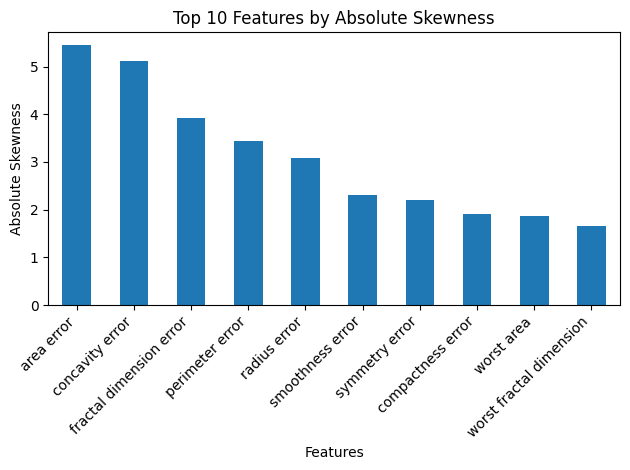

In [16]:
# TODO: describe().T, then the 10 largest skewness values
...
# Summary statistics
display(df.describe().T)

# 10 largest skewness values
skewness = df.select_dtypes(include="number").skew()
skewness.abs().sort_values(ascending=False).head(10).plot(
    kind="bar",
    title="Top 10 Features by Absolute Skewness",
    ylabel="Absolute Skewness",
    xlabel="Features"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [9]:
# TODO: correlation with target, sorted
...
correlation = df.corr(numeric_only=True)["target"].drop("target")

print("5 Most Negative Correlations:")
display(correlation.sort_values().head(5).to_frame("Correlation"))

print("5 Most Positive Correlations:")
display(correlation.sort_values(ascending=False).head(5).to_frame("Correlation"))

5 Most Negative Correlations:


,Correlation
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636


5 Most Positive Correlations:


,Correlation
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** The class proportions show that there are more benign cases than malignant cases, so I should not rely on accuracy alone. I will also check recall and the confusion matrix to make sure the model can identify malignant tumors. The skewness shows that some features have uneven distributions, so I may need to transform them. Since I am using Logistic Regression, I will start with standard scaling and check if transformations are needed.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

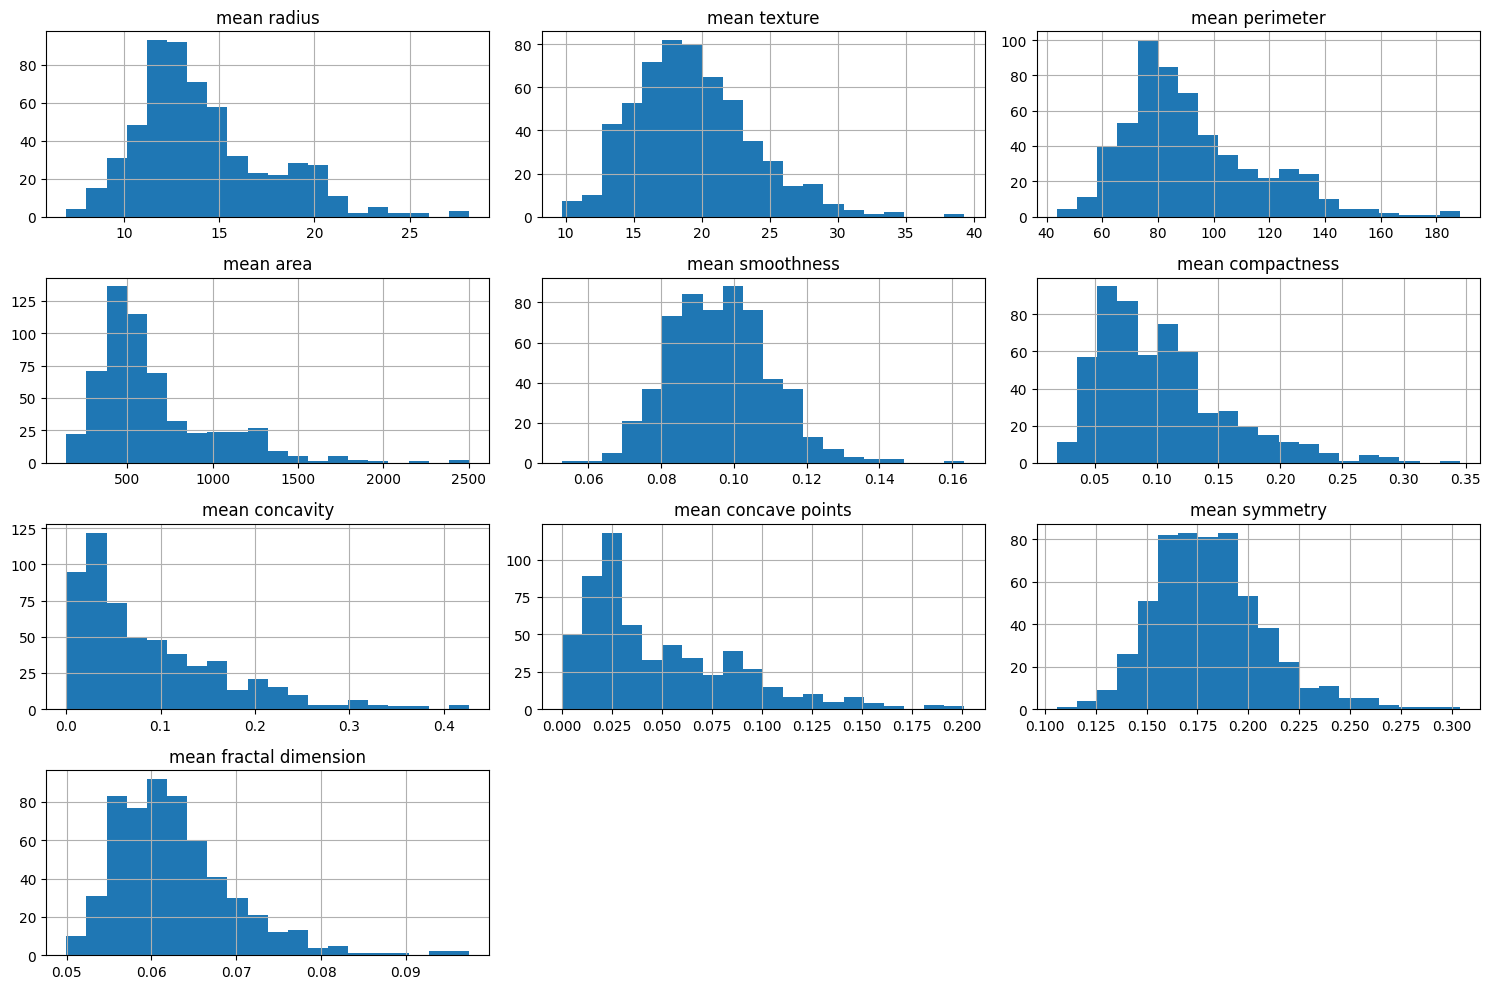

In [55]:
# @title
# Histograms of the ten "mean" features

import matplotlib.pyplot as plt

mean_features = df.filter(like="mean")

mean_features.hist(figsize=(15, 10), bins=20)

plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

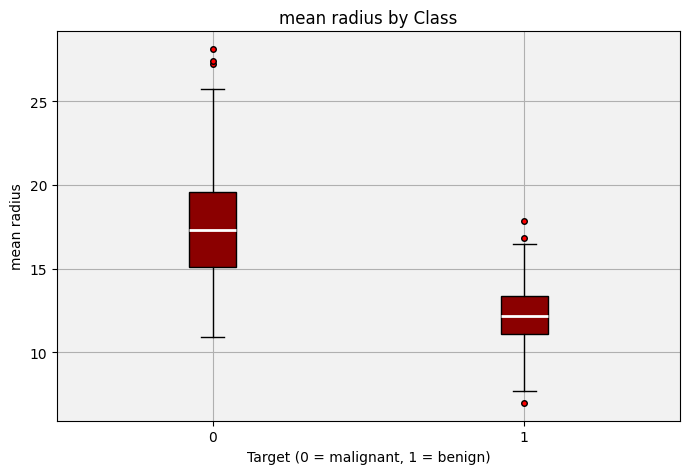

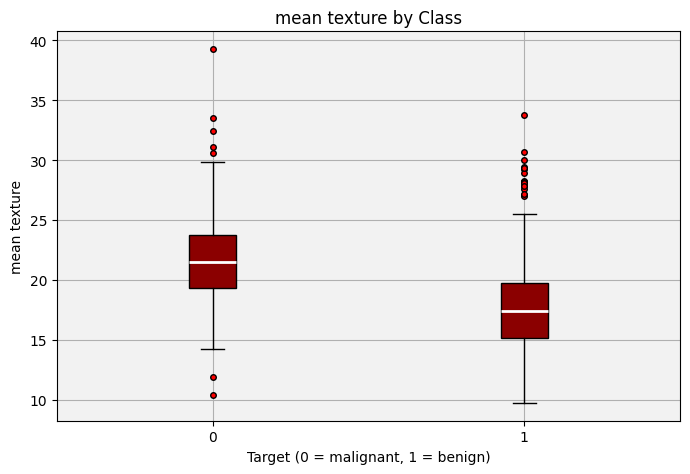

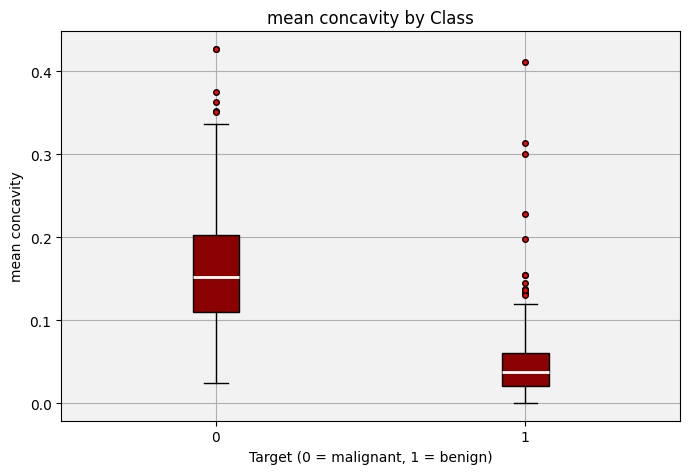

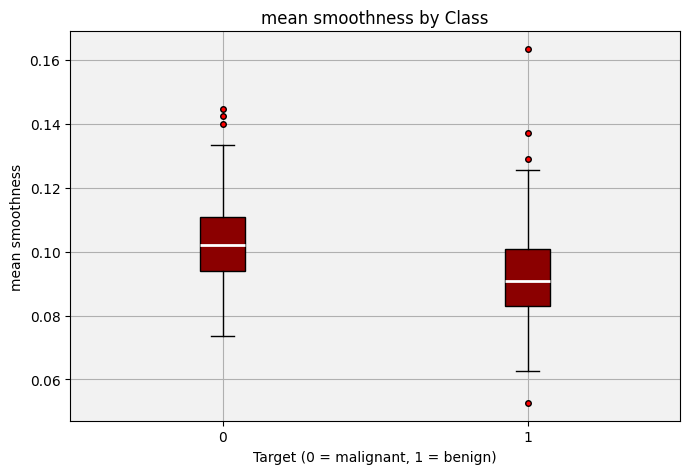

In [37]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
...
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

for feature in features:
    fig, ax = plt.subplots(figsize=(7, 5))

    df.boxplot(
        column=feature,
        by="target",
        patch_artist=True,
        boxprops=dict(facecolor="darkred", color="black"),
        medianprops=dict(color="white", linewidth=2),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        flierprops=dict(marker="o", markerfacecolor="red",
                        markeredgecolor="black", markersize=4),
        ax=ax
    )

    ax.set_title(feature + " by Class")
    fig.suptitle("")
    ax.set_xlabel("Target (0 = malignant, 1 = benign)")
    ax.set_ylabel(feature)
    ax.set_facecolor("#f2f2f2")

    plt.tight_layout()
    plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

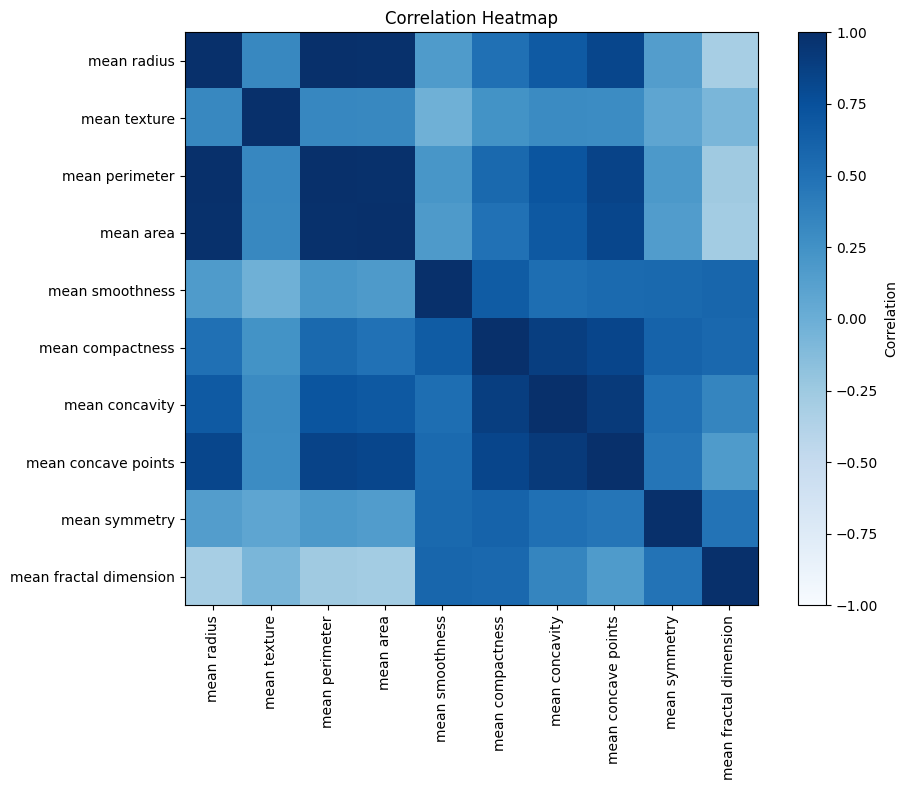

In [56]:
# TODO: correlation matrix of the "mean" features drawn with imshow
...
# Correlation matrix of the ten mean features
import matplotlib.pyplot as plt

mean_features = df.filter(like="mean")
corr = mean_features.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="Blues", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

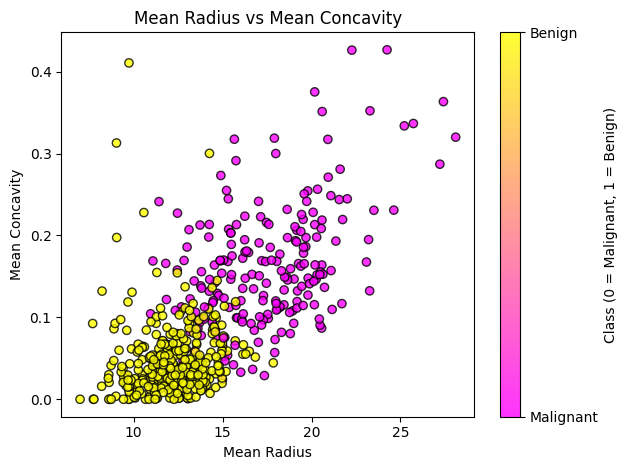

In [57]:
# TODO: coloured scatter plot with axis labels and a colourbar

import matplotlib.pyplot as plt

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="spring",
    alpha=0.8,
    edgecolors="black"
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs Mean Concavity")

cbar = plt.colorbar(scatter)
cbar.set_label("Class (0 = Malignant, 1 = Benign)")
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Malignant", "Benign"])

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:**
> 1. **Redundant Features:** Highly correlated features (correlation > 0.90 in the heatmap) are redundant. Specifically, **`mean radius`**, **`mean perimeter`**, and **`mean area`** are highly collinear because they all measure different geometric facets of tumor size. Similarly, **`mean concavity`** and **`mean concave points`** show high correlation and redundancy.

> 2. **Clear Class Separation:** Based on the box plots and target correlations, **`mean radius`** (and by extension perimeter/area) and **`mean concavity`** provide the cleanest separation between the malignant (0) and benign (1) classes, as their distributions show minimal overlap between the two targets. Conversely, features like `mean smoothness` show significant overlap across classes and are less discriminative on their own.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [41]:
# TODO: total missing values and duplicated rows
...
# Count missing values and duplicate rows
print("Total missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

# Separate features and target
X = df.drop(columns="target")
y = df["target"]


Total missing values: 0
Duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [44]:
# TODO: IQR outlier count per feature
...
# Count outliers per feature using the IQR rule
X = df.drop(columns="target")

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((X < (Q1 - 1.5 * IQR)) |
                  (X > (Q3 + 1.5 * IQR))).sum()

# Show the 10 features with the most outliers
print("Top 10 Features by IQR Outlier Count:")
display(outlier_counts.sort_values(ascending=False).head(10).to_frame("Outlier Count"))

Top 10 Features by IQR Outlier Count:


,Outlier Count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, we should not delete the outlying rows in this dataset. First, in a medical diagnostics domain, extreme values (such as an exceptionally large tumor radius, area, or high concavity) are highly likely to represent real, severe cases of malignancy rather than measurement errors or data entry noise. Removing these points would strip the model of crucial training examples for the most critical positive cases. Second, since the dataset is relatively small (569 instances), deleting rows would reduce the sample size further and weaken the statistical power of our models. Instead of removing outliers, we should use scaling techniques (like standardization or robust scaling) and models that are less sensitive to outliers.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [45]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...
# Calculate the absolute correlation matrix
X = df.drop(columns="target")
corr_abs = X.corr().abs()

# Keep only the upper triangle (excluding the diagonal)
upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.95
high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.95]

print("Feature pairs with absolute correlation > 0.95:")
display(high_corr.sort_values(ascending=False).to_frame("Absolute Correlation"))

Feature pairs with absolute correlation > 0.95:


,,Absolute Correlation
mean radius,mean perimeter,0.997855
worst radius,worst perimeter,0.993708
mean radius,mean area,0.987357
mean perimeter,mean area,0.986507
worst radius,worst area,0.984015
worst perimeter,worst area,0.977578
radius error,perimeter error,0.972794
mean perimeter,worst perimeter,0.970387
mean radius,worst radius,0.969539
mean perimeter,worst radius,0.969476


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [46]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
...
# Fit SelectKBest with the top 10 features
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

# Build and sort the feature scores
scores = pd.Series(selector.scores_, index=X.columns)
scores = scores.sort_values(ascending=False)

print("Top 10 Features Ranked by F-Score:")
display(scores.head(10).to_frame("F-Score"))

Top 10 Features Ranked by F-Score:


,F-Score
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [48]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
...
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply RFE with Logistic Regression
rfe = RFE(
    estimator=LogisticRegression(max_iter=1000),
    n_features_to_select=10
)
rfe.fit(X_scaled, y)

# Store the selected feature names
rfe_features = X.columns[rfe.support_].tolist()

print("Selected 10 Features:")
print(rfe_features)

rfe_table = pd.DataFrame({
    "No.": range(1, len(rfe_features) + 1),
    "Selected Feature": rfe_features
})

display(rfe_table)

Selected 10 Features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


,No.,Selected Feature
0,1,mean concave points
1,2,radius error
2,3,area error
3,4,compactness error
4,5,worst radius
5,6,worst texture
6,7,worst perimeter
7,8,worst area
8,9,worst concavity
9,10,worst concave points


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

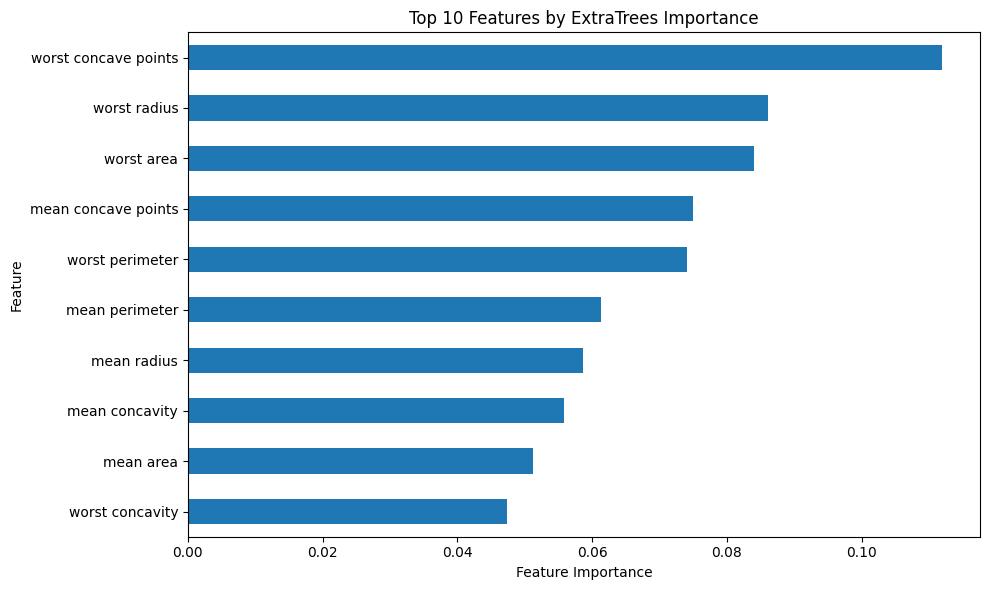

In [61]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset correctly
data = load_breast_cancer(as_frame=True)
df = data.frame

X = df.drop(columns="target")
y = df["target"].astype(int)

# Fit the model
model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)

# Rank features by importance
imp = pd.Series(model.feature_importances_, index=X.columns)
imp = imp.sort_values(ascending=False)

# Plot the top 10 features
top10 = imp.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10.plot(kind="barh")
plt.title("Top 10 Features by ExtraTrees Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [64]:
# TODO: vote across the three methods
...
#from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.ensemble import ExtraTreesClassifier

# 1. SelectKBest: top 10 features
kbest = SelectKBest(score_func=f_classif, k=10)
kbest.fit(X, y)
selected_kbest = X.columns[kbest.get_support()].tolist()

# 2. RFE: select 10 features
rfe = RFE(
    estimator=ExtraTreesClassifier(n_estimators=200, random_state=7),
    n_features_to_select=10
)
rfe.fit(X, y)
selected_rfe = X.columns[rfe.get_support()].tolist()

# 3. ExtraTrees: top 10 features
model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)
selected_extratrees = (
    pd.Series(model.feature_importances_, index=X.columns)
    .nlargest(10)
    .index.tolist()
)

# Vote across the three methods
selected = [
    feature for feature in X.columns
    if sum(feature in group for group in [
        selected_kbest, selected_rfe, selected_extratrees
    ]) >= 2
]

print("Selected features:", selected)
print("Number of selected features:", len(selected))
import pandas as pd

selected_table = pd.DataFrame({
    "Selected Features": selected
})

selected_table

Selected features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Number of selected features: 10


,Selected Features
0,mean radius
1,mean perimeter
2,mean area
3,mean concavity
4,mean concave points
5,worst radius
6,worst perimeter
7,worst area
8,worst concavity
9,worst concave points


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [65]:
# TODO: train_test_split with stratify=y
...
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X[selected],
    y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (455, 10)
Testing set: (114, 10)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [66]:
# TODO: fit both scalers on X_train and print the verifying statistics
...
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

# Fit both scalers on training data only
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

# Convert scaled data back to DataFrames
X_train_standard = pd.DataFrame(
    X_train_standard, columns=X_train.columns, index=X_train.index
)
X_train_minmax = pd.DataFrame(
    X_train_minmax, columns=X_train.columns, index=X_train.index
)

# Verify the first four features
print("StandardScaler: Mean and Standard Deviation")
print(pd.DataFrame({
    "Mean": X_train_standard.iloc[:, :4].mean(),
    "Std": X_train_standard.iloc[:, :4].std(ddof=0)
}))

print("\nMinMaxScaler: Minimum and Maximum")
print(pd.DataFrame({
    "Min": X_train_minmax.iloc[:, :4].min(),
    "Max": X_train_minmax.iloc[:, :4].max()
}))

StandardScaler: Mean and Standard Deviation
                        Mean  Std
mean radius     9.369794e-17  1.0
mean perimeter -5.797560e-16  1.0
mean area      -3.279428e-16  1.0
mean concavity -1.015061e-16  1.0

MinMaxScaler: Minimum and Maximum
                Min  Max
mean radius     0.0  1.0
mean perimeter  0.0  1.0
mean area       0.0  1.0
mean concavity  0.0  1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [67]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
...
from sklearn.decomposition import PCA
import numpy as np

# Fit PCA on standardized training data
pca = PCA()
pca.fit(X_train_standard)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components needed to retain 95% variance
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of principal components:", n_components)
print("Cumulative explained variance:", cumulative_variance[n_components - 1])

Number of principal components: 2
Cumulative explained variance: 0.9569702334339435


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [68]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
...
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Define the six candidate models
models = {
    "LR": LogisticRegression(max_iter=1000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(
            Pipeline(steps),
            X_tr,
            y_train,
            cv=kfold,
            scoring="accuracy"
        )
    return results

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [69]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
...
# Run spot-check on all features
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Calculate mean accuracies
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

summary

,raw,scaled
LR,0.940676,0.960435
LDA,0.942995,0.942995
KNN,0.916425,0.942802
CART,0.921014,0.921014
NB,0.940725,0.951691
SVM,0.905266,0.953865


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:**
> Based on the spot-check results, **KNN**, **SVM**, and **Logistic Regression (LR)** benefit significantly from scaling:
>
> 1. **KNN (K-Nearest Neighbors):** Accuracy increased from **0.916** to **0.943**. KNN computes Euclidean distance between data points. Unscaled features with larger magnitudes dominate the distance calculations, making scaling essential.
> 2. **SVM (Support Vector Machine):** Accuracy increased dramatically from **0.905** to **0.954**. SVMs maximize the margin between classes using kernel distance functions, which are highly sensitive to differing feature scales.
> 3. **Logistic Regression (LR):** Accuracy improved from **0.941** to **0.960**. Regularization terms ($L_1$ or $L_2$) penalize coefficients equally, requiring features to be on the same scale for fair regularization.
>
> **CART (Decision Trees)** do not benefit from scaling (accuracy remained exactly **0.921**), because tree-based models split nodes based on threshold rules per individual feature, making them completely scale-invariant.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [70]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...
# Spot-check using selected features only (scaled)
selected_results = spot_check(models, X_train[selected], scale=True)

# Compare with all-features scaled results
comparison = pd.DataFrame({
    "All Features (Scaled)": {
        name: scores.mean() for name, scores in scaled_results.items()
    },
    "Selected Features (Scaled)": {
        name: scores.mean() for name, scores in selected_results.items()
    }
})

comparison

,All Features (Scaled),Selected Features (Scaled)
LR,0.960435,0.960435
LDA,0.942995,0.942995
KNN,0.942802,0.942802
CART,0.921014,0.921014
NB,0.951691,0.951691
SVM,0.953865,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

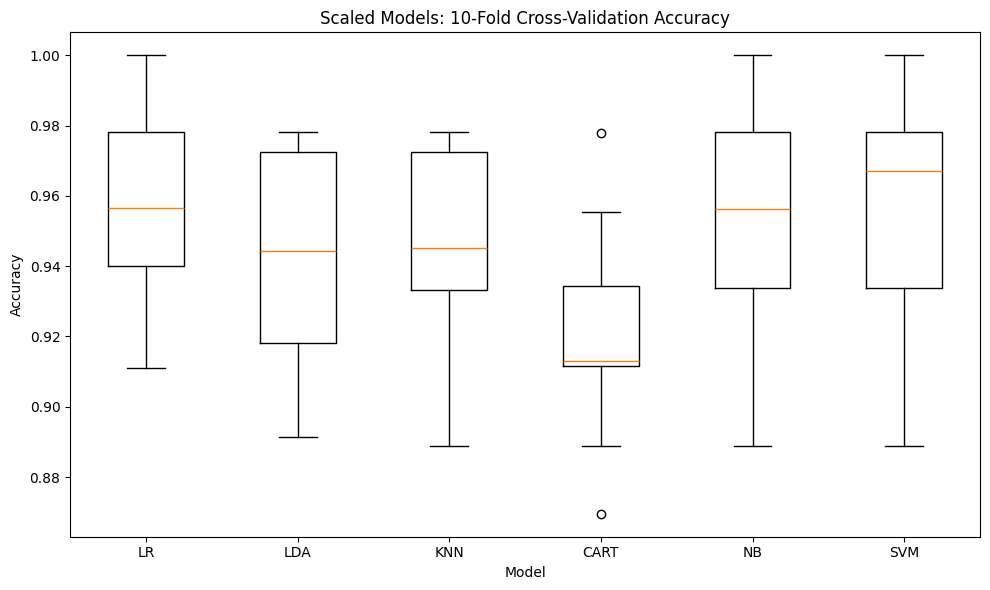

In [71]:
# TODO: box plot of the 10 fold scores per model
...
import matplotlib.pyplot as plt

# Box plot of the 10-fold cross-validation scores for scaled models
scaled_scores = [scaled_results[name] for name in models.keys()]

plt.figure(figsize=(10, 6))
plt.boxplot(scaled_scores, tick_labels=list(models.keys()))

plt.title("Scaled Models: 10-Fold Cross-Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [72]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Find the best scaled model based on mean accuracy
best_model_name = summary["scaled"].idxmax()
best_model = models[best_model_name]

print("Best scaled model:", best_model_name)

# Define scoring metrics
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": make_scorer(recall_score, pos_label=0)
}

# Pipeline keeps scaling inside each cross-validation fold
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

# Cross-validate on the training set
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

# Display mean scores
print("Mean Accuracy:", cv_results["test_accuracy"].mean())
print("Mean ROC-AUC:", cv_results["test_roc_auc"].mean())
print("Mean Malignant Recall:", cv_results["test_malignant_recall"].mean())

Best scaled model: LR
Mean Accuracy: 0.9604347826086957
Mean ROC-AUC: 0.9886627064618951
Mean Malignant Recall: 0.9470588235294117


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [74]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create a scaling pipeline
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

# Define the parameter grid
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

# Run grid search using stratified 10-fold cross-validation
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Display the best parameters and score
print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", grid.best_score_)

Best parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best cross-validation accuracy: 0.9692270531400966


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [75]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create a scaling pipeline
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

# Define the parameter grid
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

# Run grid search using stratified 10-fold cross-validation
grid_knn = GridSearchCV(
    pipeline,
    param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

# Display the best parameters and score
print("Best parameters:", grid_knn.best_params_)
print("Best cross-validation accuracy:", grid_knn.best_score_)

Best parameters: {'model__n_neighbors': 21, 'model__weights': 'uniform'}
Best cross-validation accuracy: 0.9537681159420291


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [76]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Define the four ensemble methods
ensembles = {
    "RF": RandomForestClassifier(n_estimators=200, random_state=7),
    "ET": ExtraTreesClassifier(n_estimators=200, random_state=7),
    "GB": GradientBoostingClassifier(random_state=7),
    "AdaBoost": AdaBoostClassifier(random_state=7)
}

# Score the four ensemble methods
ensemble_results = spot_check(ensembles, X_train, scale=False)

# Create a hard voting ensemble using the tuned SVM, tuned KNN, and Random Forest
voting = VotingClassifier(
    estimators=[
        ("svm", grid.best_estimator_),
        ("knn", grid_knn.best_estimator_),
        ("rf", ensembles["RF"])
    ],
    voting="hard"
)

# Add the voting ensemble
ensembles["Voting"] = voting

# Score all five ensemble methods
ensemble_results = spot_check(ensembles, X_train, scale=False)

# Display mean accuracy for each ensemble
ensemble_summary = pd.DataFrame({
    "Mean Accuracy": {
        name: scores.mean()
        for name, scores in ensemble_results.items()
    }
})

ensemble_summary

,Mean Accuracy
RF,0.951643
ET,0.953865
GB,0.947246
AdaBoost,0.945072
Voting,0.964831


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [77]:
# TODO: leaderboard Series
...
# Build a leaderboard using mean 10-fold CV accuracy
leaderboard = pd.Series({
    "Tuned SVM": grid.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    **{
        name: scores.mean()
        for name, scores in ensemble_results.items()
    }
}).sort_values(ascending=False)

leaderboard

,0
Tuned SVM,0.969227
Voting,0.964831
ET,0.953865
Tuned KNN,0.953768
RF,0.951643
GB,0.947246
AdaBoost,0.945072


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Test Accuracy: 0.9385964912280702

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.91      0.93      0.92        42
      Benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



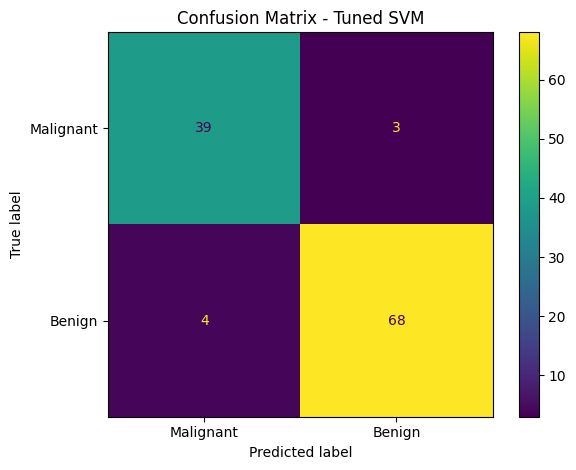

In [78]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the leaderboard winner
winner_name = leaderboard.index[0]

# Select the winning model
if winner_name == "Tuned SVM":
    winner = grid.best_estimator_
elif winner_name == "Tuned KNN":
    winner = grid_knn.best_estimator_
else:
    winner = ensembles[winner_name]

# Fit on the full training set
winner.fit(X_train, y_train)

# Evaluate on the held-out test set (only once)
y_pred = winner.predict(X_test)

print("Winning Model:", winner_name)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

display.plot()
plt.title(f"Confusion Matrix - {winner_name}")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [79]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...
import joblib
import numpy as np

# Save the trained winning model
joblib.dump(winner, "best_model.joblib")

# Reload the saved model
loaded_model = joblib.load("best_model.joblib")

# Compare the first 5 predictions with y_test
original_predictions = winner.predict(X_test.iloc[:5])
loaded_predictions = loaded_model.predict(X_test.iloc[:5])
actual_values = y_test.iloc[:5].to_numpy()

print("Actual values:       ", actual_values)
print("Original predictions:", original_predictions)
print("Loaded predictions:  ", loaded_predictions)

# Confirm predictions are identical
print("\nPredictions match:", np.array_equal(
    original_predictions, loaded_predictions
))

Actual values:        [0 0 1 0 1]
Original predictions: [0 0 1 0 1]
Loaded predictions:   [0 0 1 0 1]

Predictions match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.